In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib as mpl
import xml.etree.ElementTree as ET
import shapely
import cartopy
import pyproj
import numpy
from math import sin,cos,radians
from pathlib import Path
from datetime import datetime

In [2]:
title = "Seduisant WNR Series 2 8/26/2026"
outfileBase = "Seduisant WNR Series 2 2026-08-26"
outputPath = "./output/Seduisant"

waypointFile = "./tracks/Pontchartrain Waypoints_2026-05-14.gpx"
trackFile = "./tracks/Track_2026-08-26 201144.gpx"
windFile = "./windData/nwcl1_2026-09-02.pickle"
proj = cartopy.crs.Mercator()
buffer = 0.25 / 60 #buffer in nautical miles
nm2Meter = 1852.0

In [3]:
wgs84 = pyproj.crs.CRS.from_string('WGS84')
utm = pyproj.crs.CRS.from_string('EPSG:32615')

In [4]:
Path(outputPath).mkdir(exist_ok=True,parents=True)

In [5]:
waypointXML = ET.parse(waypointFile)

In [6]:
wptList = []
for child in waypointXML.getroot().findall('{http://www.topografix.com/GPX/1/1}wpt'):
    data = {
                'name':child.find('{http://www.topografix.com/GPX/1/1}name').text,
                'geometry':shapely.Point(child.attrib['lon'],child.attrib['lat'])
    }
    
    
    wptList.append(data)

waypointGdf = gpd.GeoDataFrame(data= pd.DataFrame.from_dict(wptList), geometry='geometry', crs=wgs84)

In [7]:
waypointGdf.drop_duplicates(subset=['name'], inplace=True)

In [8]:
waypointGdf['name'] = waypointGdf['name'].str.replace('"','').str.replace('SYC ','')
waypointGdf['name'] = waypointGdf['name'].str.replace('"','').str.replace(' Corrected','')

In [9]:
waypointGdf.set_index('name', inplace=True)

In [10]:
waypointGdf.index

Index(['Bayou Bonfouca', 'Cause South Hump', 'Causway Bridge',
       'Goose Point Piling', 'L1', 'M1', 'Madisonville', 'Mandeville',
       'New Orleans', 'North Draw #2', 'PYC J', 'PYC P', 'PYC S',
       'SL1_2018-06-30 101554', 'SL2_2018-06-30 101554', 'SSH', 'A', 'B', 'C',
       'D', 'E', 'F', 'G', 'H', 'Lamda', 'M', 'P', 'R', 'S', 'T', 'U', 'V',
       'W', 'X', 'Y', 'Z', 'US 11 Bridge', 'Little J', 'J'],
      dtype='str', name='name')

In [11]:
#map is two busy filter out points that dont matter
waypointGdf = waypointGdf[waypointGdf.index.isin(['A','T','S','C','B'])].copy()

In [12]:
waypointGdf.index

Index(['A', 'B', 'C', 'S', 'T'], dtype='str', name='name')

In [13]:
trkXML = ET.parse(trackFile)

In [14]:
trkSegXML = trkXML.getroot().find('{http://www.topografix.com/GPX/1/1}trk').\
    find('{http://www.topografix.com/GPX/1/1}trkseg')

In [15]:
trkList = []
for child in trkSegXML:
    data = {
                'time':child.find('{http://www.topografix.com/GPX/1/1}time').text,
                'geometry':shapely.Point(child.attrib['lon'],child.attrib['lat'])
           }
    
    trkList.append(data)

trkGdf = gpd.GeoDataFrame(data=pd.DataFrame.from_dict(trkList), geometry='geometry', crs=wgs84)

In [16]:
trkGdf['time'] = pd.to_datetime( trkGdf['time'] ).dt.tz_convert('US/Central')
print(f"Start time {trkGdf['time'].min()}")

Start time 2026-08-26 18:43:19-05:00


In [17]:
trkGdf['timeDelta'] = trkGdf['time'] - trkGdf['time'].shift(1)
trkGdf['timeCumsum'] = trkGdf['timeDelta'].cumsum()
print(f"Mean time between measure {trkGdf['timeDelta'].mean()}")

Mean time between measure 0 days 00:00:07.198100


In [18]:
geod = pyproj.Geod(ellps='clrk66')
print(f"Total distance {geod.line_length(trkGdf['geometry'].x, trkGdf['geometry'].y) / nm2Meter}nm")

Total distance 5.619471702445055nm


In [19]:
trkGdf['bearing'] = geod.inv(trkGdf['geometry'].x,trkGdf['geometry'].y, trkGdf['geometry'].shift(1).x, trkGdf['geometry'].shift(1).y)[1]

In [20]:
mask = trkGdf['bearing'] < 0
trkGdf.loc[mask, 'bearing'] = trkGdf['bearing'][mask] + 360.0

In [21]:
trkGdf['delta_distance'] = numpy.nan
trkGdf.loc[1:,'delta_distance'] = geod.line_lengths(trkGdf['geometry'].x, trkGdf['geometry'].y) / nm2Meter

In [22]:
trkGdf['dist_cumsum'] = trkGdf['delta_distance'].cumsum()

In [23]:
trkGdf['delta_distance'].sum()

np.float64(5.619471702445052)

In [24]:
trkGdf['speed'] = (60.0 * 60.0 * trkGdf['delta_distance']) / trkGdf['timeDelta'].dt.total_seconds()

In [25]:
print(f"speed max:{trkGdf['speed'].max()}\tmin:{trkGdf['speed'].min()}\tmean:{trkGdf['speed'].mean()}")

speed max:9.781360805781972	min:0.060670433237130526	mean:4.565116889706157


In [26]:
trkGdf.set_index('time',inplace=True)

In [27]:
trkGdf = trkGdf[numpy.logical_and( trkGdf.index>'2026-08-26 19:05:00-05:00',\
                                   trkGdf.index<'2026-08-26 19:53:43-05:00')].copy()

In [28]:
trkGdf.head()

,geometry,timeDelta,timeCumsum,bearing,delta_distance,dist_cumsum,speed
time,,,,,,,
2026-08-26 19:05:02-05:00,POINT (-90.10107 30.03283),0 days 00:00:07,0 days 00:21:43,60.444953,0.008004,1.038499,4.116592
2026-08-26 19:05:08-05:00,POINT (-90.10094 30.03289),0 days 00:00:06,0 days 00:21:49,64.797550,0.007305,1.045804,4.382813
2026-08-26 19:05:17-05:00,POINT (-90.10072 30.03294),0 days 00:00:09,0 days 00:21:58,74.372867,0.012013,1.057816,4.805031
2026-08-26 19:05:24-05:00,POINT (-90.10057 30.03299),0 days 00:00:07,0 days 00:22:05,68.279159,0.008473,1.066289,4.357301
2026-08-26 19:05:33-05:00,POINT (-90.10048 30.03311),0 days 00:00:09,0 days 00:22:14,34.542779,0.008484,1.074773,3.393704


In [29]:
windDf = pd.read_pickle(windFile)
mask = numpy.logical_and( (windDf.index >= trkGdf.index.min()),\
                        windDf.index <= trkGdf.index.max())
windDf = windDf[mask].copy()
medianWind = windDf['WDIR'].median()
meanWindSpeed = windDf['WSPD'].mean()
print(f"Median wind direction: {medianWind}")
print(f"Mean wind speed:  {meanWindSpeed}")
windDf.head()

Median wind direction: 200.0
Mean wind speed:  2.4375


,#YY,MM,DD,hh,mm,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,PTDY,TIDE
2026-08-26 19:48:00-05:00,2026,8,27,0,48,200,3.6,4.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-08-26 19:42:00-05:00,2026,8,27,0,42,200,3.1,6.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-08-26 19:36:00-05:00,2026,8,27,0,36,190,4.1,6.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-08-26 19:30:00-05:00,2026,8,27,0,30,200,4.1,5.7,NaN,NaN,NaN,NaN,1012.5,31.7,33.1,NaN,NaN,NaN,NaN
2026-08-26 19:24:00-05:00,2026,8,27,0,24,190,3.6,5.7,NaN,NaN,NaN,NaN,1012.5,32.0,33.1,NaN,NaN,NaN,NaN


In [30]:
def createWindQuiver(ax):
    
    arrowRows = 20
    axExtent = ax.get_extent()
    lonMin = axExtent[0]
    lonMax = axExtent[1]
    lonRange = numpy.arange(lonMin,lonMax, (lonMax-lonMin)/arrowRows)
    latMin = axExtent[2]
    latMax = axExtent[3]
    latRange = numpy.arange(latMin,latMax, (latMax-latMin)/arrowRows)
    
    (lonMesh,latMesh) = numpy.meshgrid(lonRange, latRange)
    ax.quiver(x=lonMesh,y=latMesh,\
              u=sin(radians(medianWind+180)),v=cos(radians(medianWind+180)),\
              angles='uv',\
              color =(0,0,0,0.2),
              zorder=-2,
              label=f"Wind Dir {medianWind:.0f}\U000000B0")


In [31]:
def createPlot(ax, extent, s=72, wpS=500,plotWind=True, lblWpt=True ,extentBuffer=buffer, df=trkGdf,colorMap=mpl.cm.magma):
    
    boundBox = shapely.geometry.box(*extent)
    #wptMask = waypointGdf['geometry'].map(lambda pt: boundBox.contains(pt))
    
    tmDelta = pd.Timedelta('1 minute')
    for tm in dirArrowTimes:
        pt1 = df['geometry'].asof(tm)
        pt2 = df['geometry'].asof(tm+tmDelta)
        arrowBuffer = 0.001
        arrow = mpl.patches.FancyArrowPatch( (pt1.x-arrowBuffer, pt1.y+arrowBuffer), (pt2.x-arrowBuffer, pt2.y+arrowBuffer) ,mutation_scale=20, zorder=-1      )
        ax.add_patch(arrow)
    
    
    ax.scatter(waypointGdf.geometry.x, waypointGdf.geometry.y, marker='s',s=wpS, c='r', label='Marker')

    if lblWpt:
        for idx,item in waypointGdf.iterrows():
            ax.text(item['geometry'].x,item['geometry'].y,idx, va='center', ha='center', fontsize='20', fontname='serif',c='b' )
    
    ax.set_xlim(extent[0]-extentBuffer, extent[2]+extentBuffer)
    ax.set_ylim(extent[1]-extentBuffer, extent[3]+extentBuffer)
    ax.coastlines()
    
    
    trkPlt = ax.scatter(df.geometry.x,df.geometry.y, c=colorMap(norm(df['speed'])), s=s,zorder=5)
    
    if plotWind:
        createWindQuiver(ax)




In [32]:
dirArrowTimes = pd.date_range(start=trkGdf.index[0], end=trkGdf.index[-1], periods=6)[1:]

In [33]:
waypointGdf.index

Index(['A', 'B', 'C', 'S', 'T'], dtype='str', name='name')

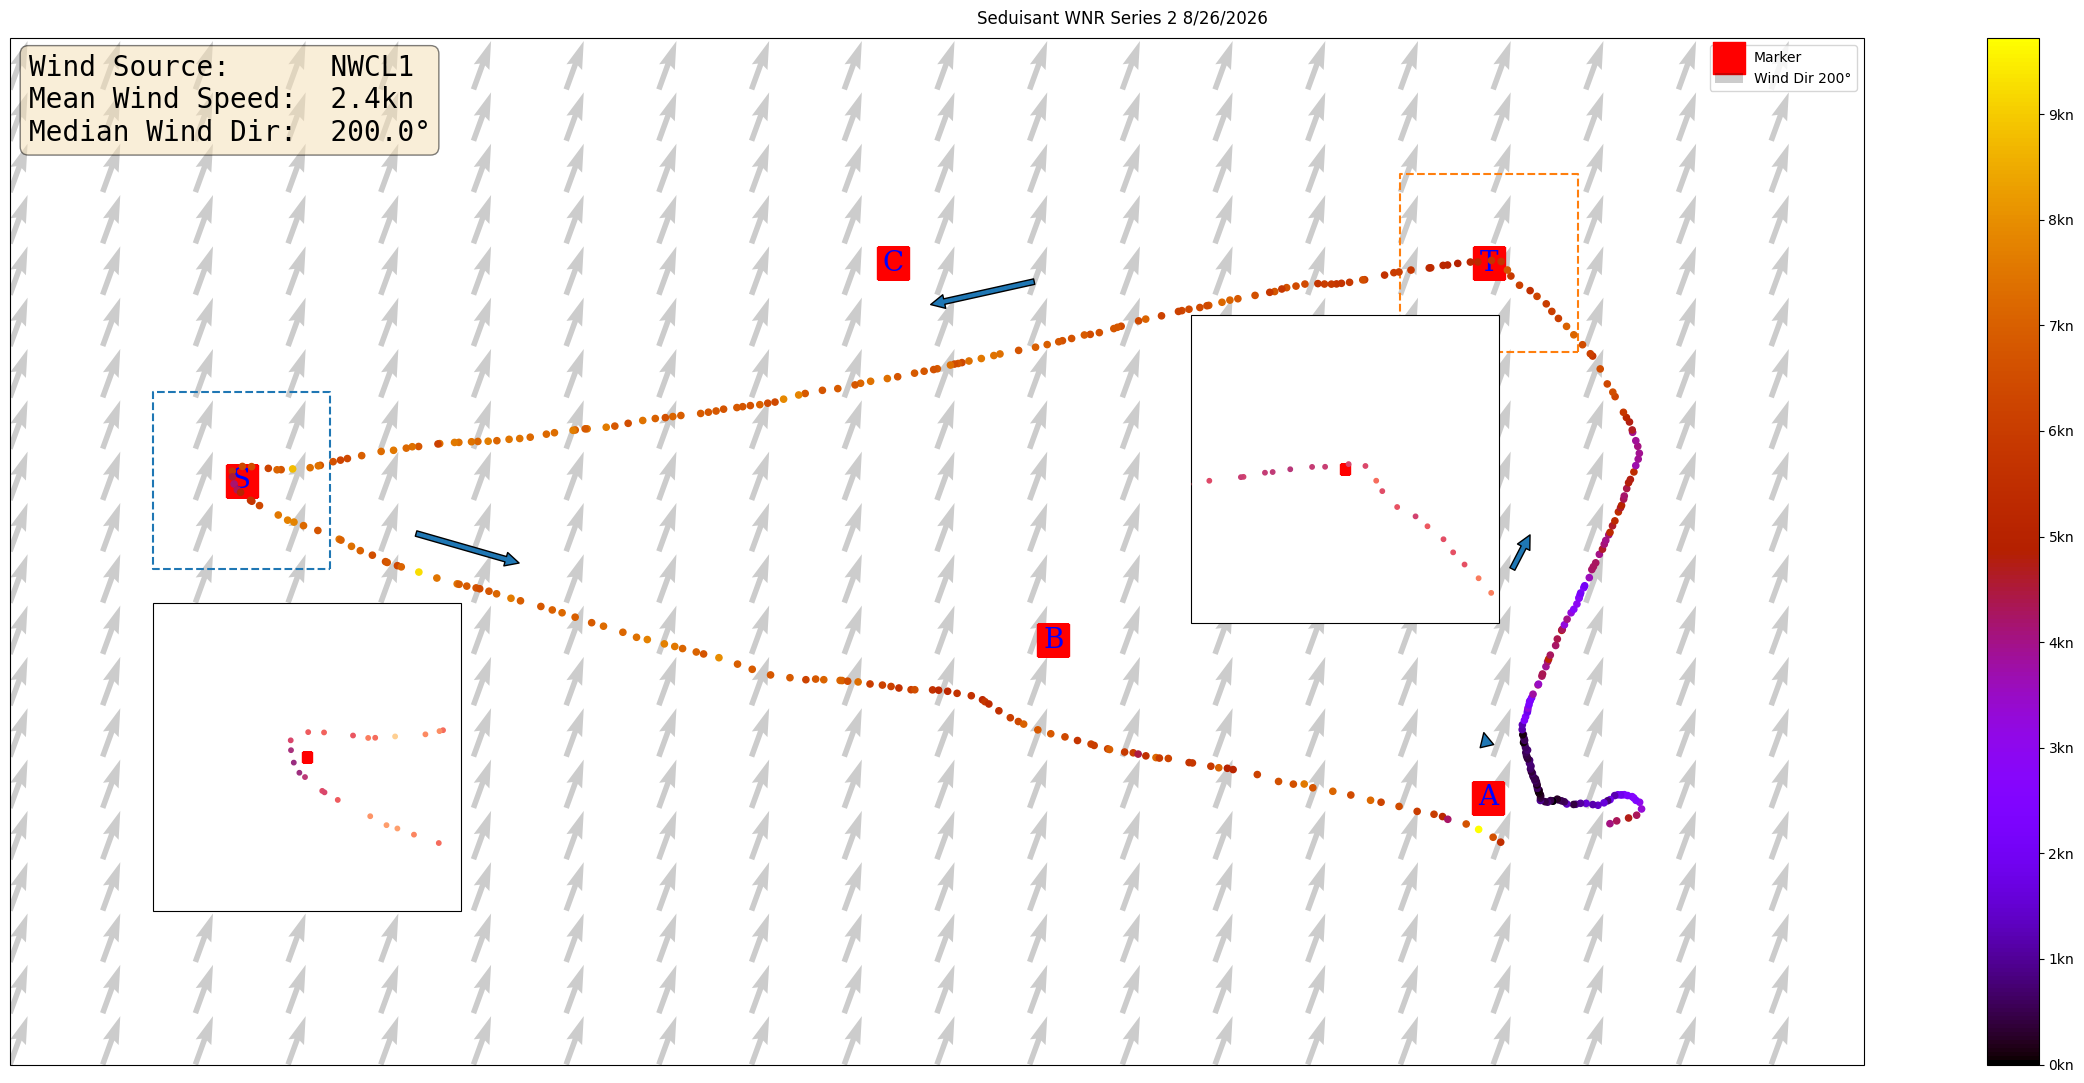

In [34]:
figsize = (25,11)
fig,ax = plt.subplots(1, figsize=figsize ,subplot_kw={'projection': proj})

norm = mpl.colors.Normalize(vmin=trkGdf['speed'].min(), vmax = trkGdf['speed'].max(), clip=True)
colorbarTicks = numpy.arange(norm.vmin,norm.vmax+0.001,1.0)
colorMap = mpl.cm.gnuplot
cax = fig.colorbar( plt.cm.ScalarMappable(norm=norm, cmap=colorMap), ax=ax)   
cax.set_ticks(colorbarTicks)
cax.set_ticklabels( [f"{int(i)}kn" for i in colorbarTicks])

createPlot(ax,s=20, extent=trkGdf.total_bounds,colorMap=colorMap)


wptRadius = 0.1 / 60
gExtent = waypointGdf.loc['S','geometry'].buffer(wptRadius).bounds
gBox = shapely.geometry.box(*gExtent)
ax.plot(gBox.exterior.xy[0],gBox.exterior.xy[1],zorder=4,linestyle='--')
gInset = ax.inset_axes([0.01,0.15,0.3,0.3], projection=proj, zorder=10 )
createPlot(gInset, gExtent, s=10, wpS=50, plotWind=False, lblWpt=False, extentBuffer=0 )

wptRadius = 0.1 / 60
gExtent = waypointGdf.loc['T','geometry'].buffer(wptRadius).bounds
gBox = shapely.geometry.box(*gExtent)
ax.plot(gBox.exterior.xy[0],gBox.exterior.xy[1],zorder=4,linestyle='--')
gInset = ax.inset_axes([0.57,0.43,0.3,0.3], projection=proj, zorder=10 )
createPlot(gInset, gExtent, s=10, wpS=50, plotWind=False, lblWpt=False, extentBuffer=0 )


#add wind speed
windStr = f"""Wind Source:      NWCL1
Mean Wind Speed:  {meanWindSpeed:.1f}kn
Median Wind Dir:  {medianWind}\U000000B0"""
ax.text(0.01,0.9,windStr, transform=ax.transAxes,\
        fontsize=20,\
        fontfamily='monospace',\
       bbox={
           'boxstyle':'round',
           'facecolor':'wheat',
           'alpha':0.5
       })

ax.legend()

fig.suptitle(title)
fig.tight_layout()
fig.savefig(f"{outputPath}/{outfileBase}.jpg")
fig.savefig(f"{outputPath}/{outfileBase}.svg")

In [35]:
print(datetime.now())

2026-09-02 13:20:08.978021
